In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset after encoding
df = pd.read_csv("C:/Users/USER/Desktop/2025-Y2-S1-MLB-B5G1-04/Results/outputs/encoded.csv")

In [4]:
numerical_cols = df.select_dtypes(include='number').columns
print("Numerical Columns:", numerical_cols.tolist())

Numerical Columns: ['Unnamed: 0', 'Age', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Total_Cholesterol', 'HDL_Cholesterol', 'LDL_Cholesterol', 'Triglycerides', 'Smoking_Status', 'Physical_Activity_Level']


In [5]:
Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

# Boolean mask for outliers
outlier_mask = (df[numerical_cols] < (Q1 - 1.5 * IQR)) | (df[numerical_cols] > (Q3 + 1.5 * IQR))
print(outlier_mask.sum())   # Number of outliers per column

Unnamed: 0                   0
Age                          0
BMI                        187
Systolic_BP                174
Diastolic_BP               161
Total_Cholesterol          172
HDL_Cholesterol            207
LDL_Cholesterol            187
Triglycerides              197
Smoking_Status               0
Physical_Activity_Level      0
dtype: int64


In [6]:
df_out = df[~((df[numerical_cols] < (Q1 - 1.5 * IQR)) | 
              (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Shape before:", df.shape)
print("Shape after removing outliers:", df_out.shape)

Shape before: (25000, 11)
Shape after removing outliers: (23807, 11)


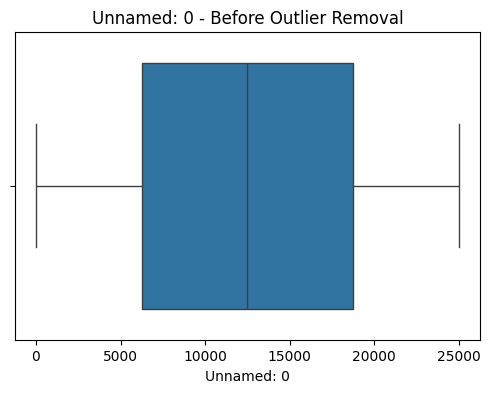

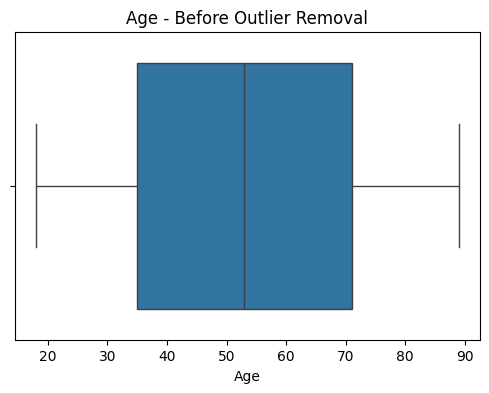

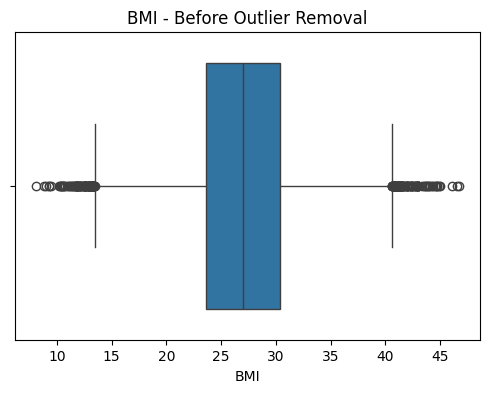

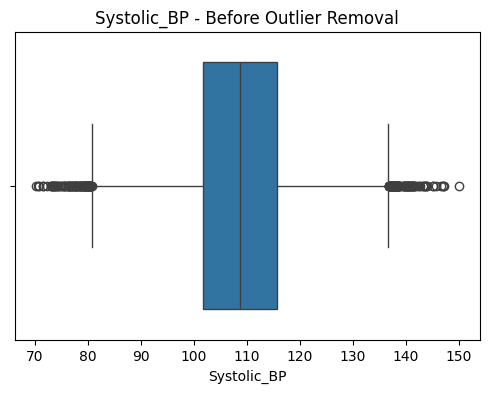

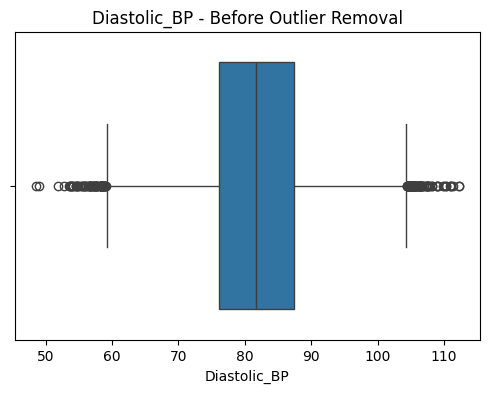

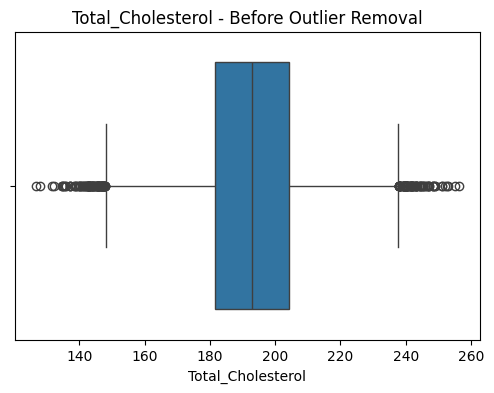

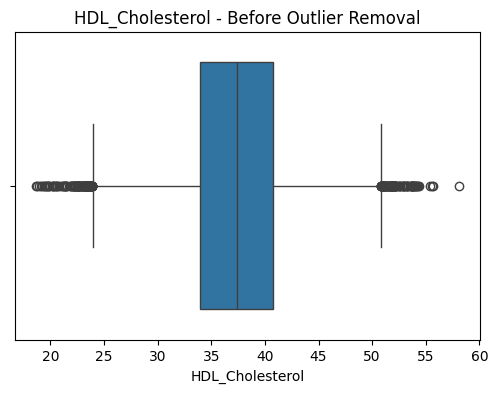

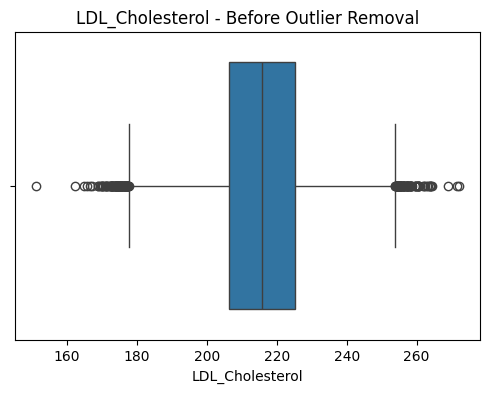

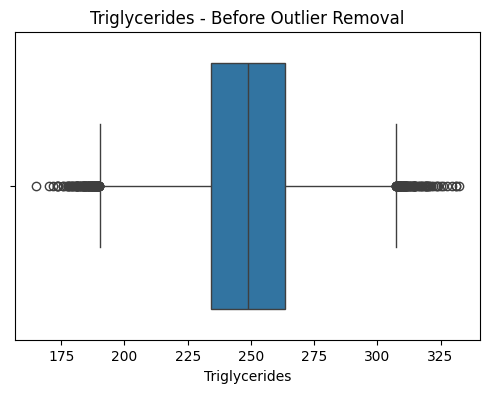

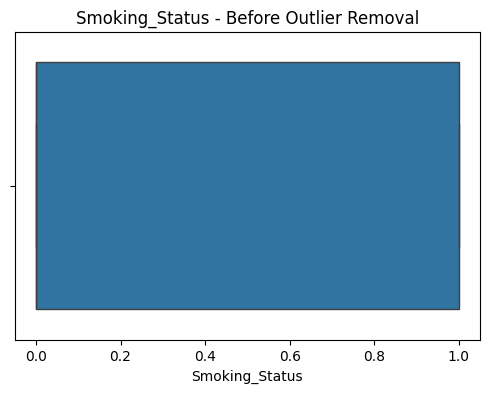

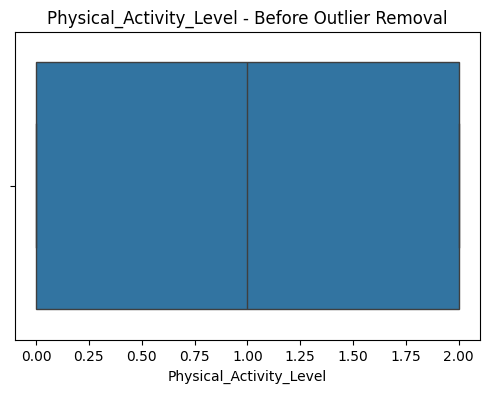

In [8]:
#Boxplots before outlier removal
for col in numerical_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"{col} - Before Outlier Removal")

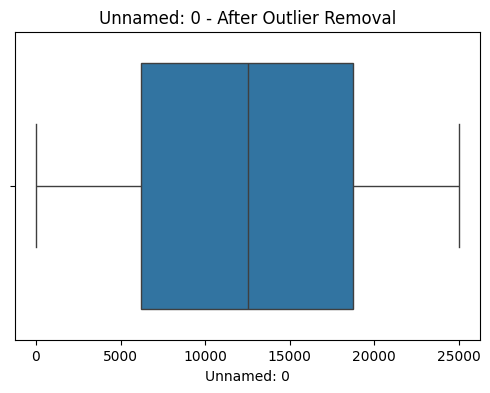

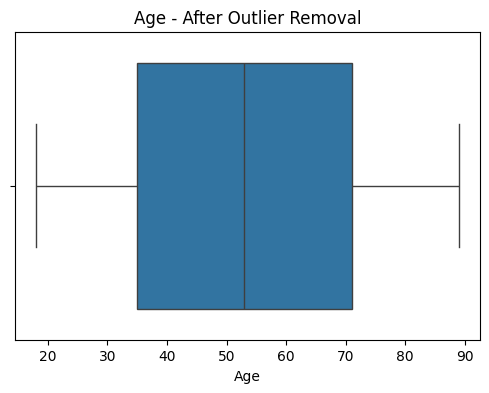

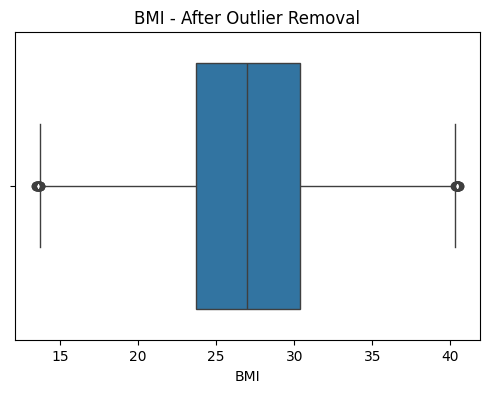

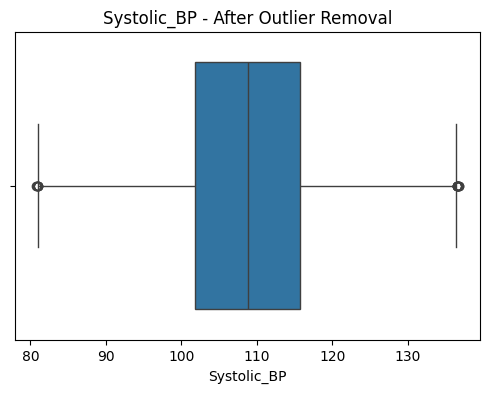

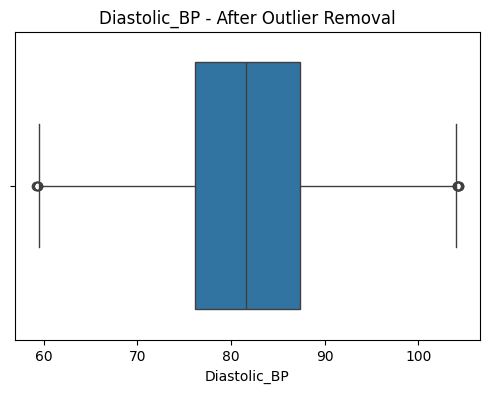

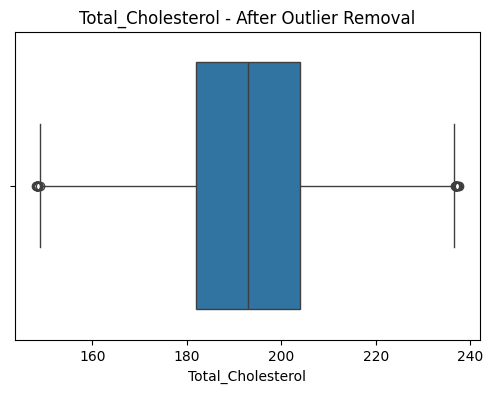

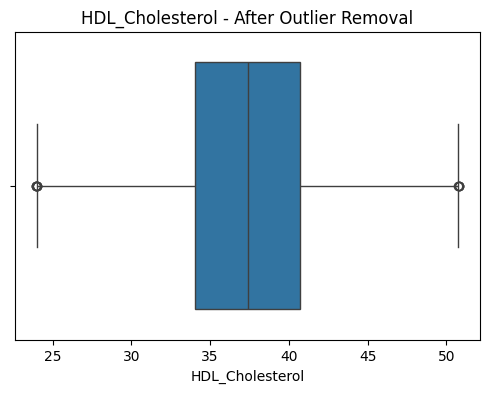

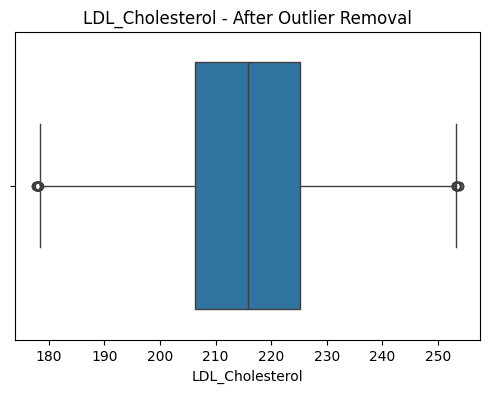

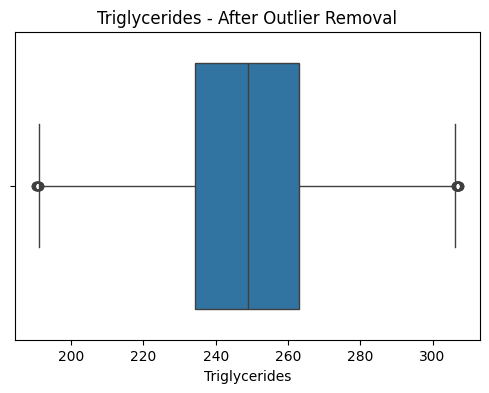

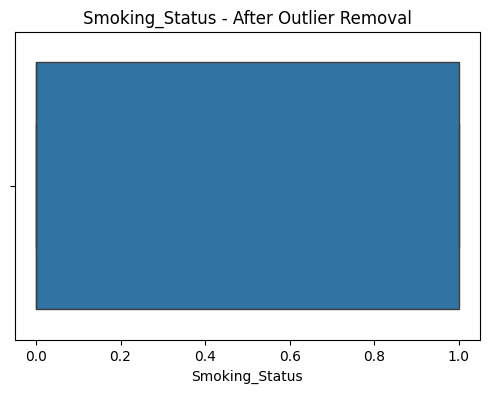

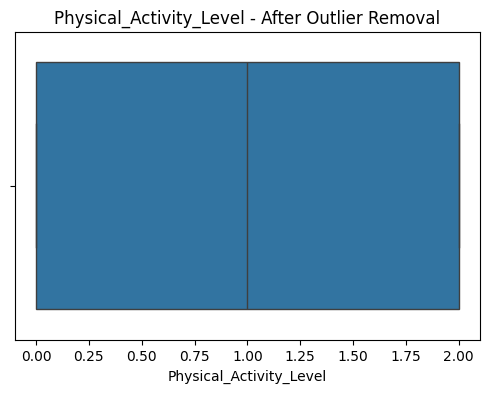

In [9]:
#Boxplots after outlier removal
for col in numerical_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df_out[col])
    plt.title(f"{col} - After Outlier Removal")

In [10]:
# Save encoded dataset
df.to_csv("C:/Users/USER/Desktop/2025-Y2-S1-MLB-B5G1-04/Results/outputs/OutliersRemoved.csv", index=False)